In [8]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]



TUNING: RNN


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Best Hyperparameters: {'units': 32, 'learning_rate': 0.01}
Test Loss: 5.770855932496488e-05

TUNING: LSTM
Best Hyperparameters: {'units': 32, 'learning_rate': 0.01}
Test Loss: 2.384441813774174e-06

TUNING: GRU
Best Hyperparameters: {'units': 64, 'learning_rate': 0.01}
Test Loss: 1.314721430389909e-06

MODEL COMPARISON
RNN Loss: 5.770855932496488e-05
LSTM Loss: 2.384441813774174e-06
GRU Loss: 1.314721430389909e-06


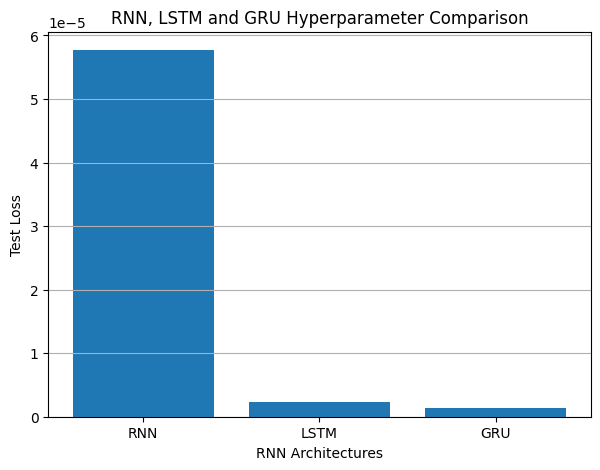

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt

np.random.seed(42)
tf.random.set_seed(42)

# 1. Generate sequential dataset
data = np.sin(
    np.linspace(0, 50, 500)
)

# 2. Create sequences
def create_sequences(data, steps):

    X, y = [], []

    for i in range(len(data) - steps):

        X.append(data[i:i + steps])

        y.append(data[i + steps])

    return np.array(X), np.array(y)

steps = 15

X, y = create_sequences(data, steps)

X = X.reshape(-1, steps, 1)

# 3. Split dataset
split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# 4. Define model builder
def build_model(hp, model_type):

    model = tf.keras.Sequential()

    model.add(
        tf.keras.layers.Input(
            shape=(steps, 1)
        )
    )

    units = hp.Choice(
        "units",
        [16, 32, 64]
    )

    learning_rate = hp.Choice(
        "learning_rate",
        [0.001, 0.01]
    )

    if model_type == "RNN":

        model.add(
            tf.keras.layers.SimpleRNN(
                units
            )
        )

    elif model_type == "LSTM":

        model.add(
            tf.keras.layers.LSTM(
                units
            )
        )

    elif model_type == "GRU":

        model.add(
            tf.keras.layers.GRU(
                units
            )
        )

    model.add(
        tf.keras.layers.Dense(1)
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

# 5. Perform hyperparameter tuning
results = {}

for model_type in ["RNN", "LSTM", "GRU"]:

    print("\nTUNING:", model_type)

    tuner = kt.RandomSearch(
        hypermodel=lambda hp: build_model(
            hp, model_type
        ),
        objective="val_loss",
        max_trials=3,
        executions_per_trial=1,
        directory="DL_Tuning",
        project_name=model_type,
        overwrite=True
    )

    tuner.search(
        X_train,
        y_train,
        epochs=10,
        validation_split=0.2,
        batch_size=16,
        verbose=0
    )

    # Get best model
    best_model = tuner.get_best_models(
        num_models=1
    )[0]

    # Evaluate model
    test_loss = best_model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    results[model_type] = test_loss

    print(
        "Best Hyperparameters:",
        tuner.get_best_hyperparameters(1)[0].values
    )

    print("Test Loss:", test_loss)

# 6. Compare models
print("\nMODEL COMPARISON")

for name, loss in results.items():

    print(name, "Loss:", loss)

# 7. Plot results
plt.figure(figsize=(7, 5))

plt.bar(
    list(results.keys()),
    list(results.values())
)

plt.xlabel("RNN Architectures")
plt.ylabel("Test Loss")

plt.title(
    "RNN, LSTM and GRU Hyperparameter Comparison"
)

plt.grid(axis="y")

plt.show()